In [17]:
print('金融2502-张耀鹏-U202515714')
print("第一章：数据基本结构")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans
df1=pd.read_csv('exercise1_2.csv' , encoding='gbk')
table1=pd.crosstab(index=df1['Sex'],columns=df1['Survived'], margins = True,margins_name='总计')
print('##### (1) Sex 与 Survived 的二维列联表 #####')
table1

金融2502-张耀鹏-U202515714
第一章：数据基本结构
##### (1) Sex 与 Survived 的二维列联表 #####


Survived,No,Yes,总计
Sex,,,
Female,126,344,470
Male,1364,367,1731
总计,1490,711,2201


In [2]:
table2=pd.crosstab(index=[df1['Class'],df1['Sex']],columns=[df1['Age'],df1['Survived']])
print('##### (2) 多维列联表 #####')
table2

##### (2) 多维列联表 #####


Age          Adult      Child    
Survived        No  Yes    No Yes
Class Sex                        
1st   Female     4  140     0   1
      Male     118   57     0   5
2nd   Female    13   80     0  13
      Male     154   14     0  11
3rd   Female    89   76    17  14
      Male     387   75    35  13
Crew  Female     3   20     0   0
      Male     670  192     0   0

第二章：数据可视化


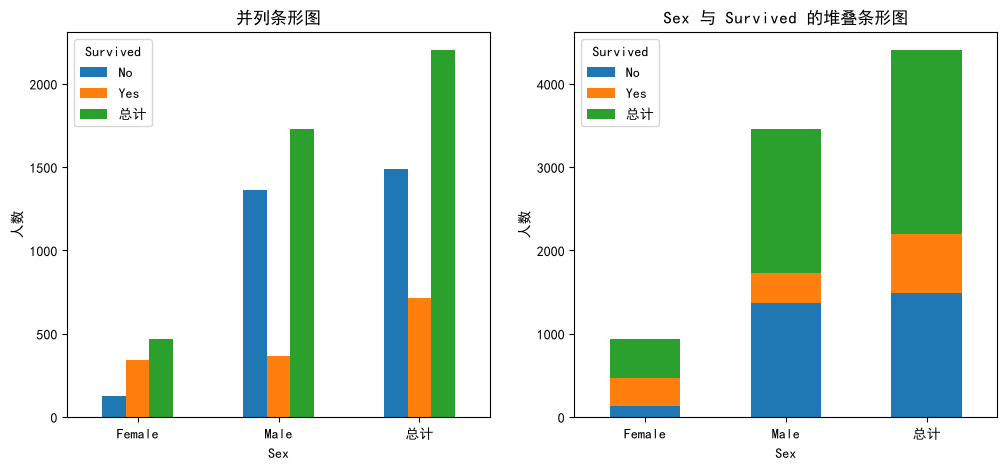

In [3]:
print('第二章：数据可视化')
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
df2=pd.read_csv('exercise2_1.csv',index_col=0)
fig,axes = plt.subplots(1,2, figsize=(12,5))
table1.plot(kind='bar',ax=axes[0],rot=0)
axes[0].set_title('并列条形图')
axes[0].set_xlabel('Sex')
axes[0].set_ylabel('人数')
axes[0].legend(title='Survived')
table1.plot(kind='bar',stacked=True,ax=axes[1],rot=0)
axes[1].set_title('Sex 与 Survived 的堆叠条形图')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('人数')
axes[1].legend(title='Survived')
plt.show()

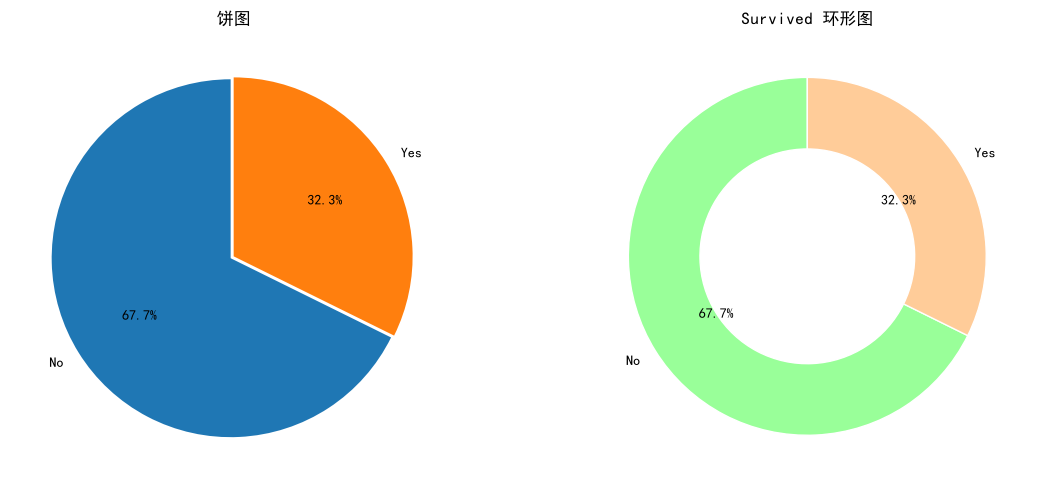

In [4]:
survived_counts= df1['Survived'].value_counts()
fig, axes = plt.subplots(1,2, figsize = (12,5))
axes[0].pie(survived_counts,labels=survived_counts.index,autopct="%1.1f%%",startangle= 90, explode=(0.02,0))
axes[0].set_title("饼图")
axes[1].pie(survived_counts, 
            labels=survived_counts.index, 
            autopct='%1.1f%%', 
            startangle=90, 
            colors=['#99ff99', '#ffcc99'],
            wedgeprops=dict(width=0.4, edgecolor='w')) 
axes[1].set_title('Survived 环形图')
plt.tight_layout()
plt.show()

ValueError: Could not interpret value `eruptions` for `x`. An entry with this name does not appear in `data`.

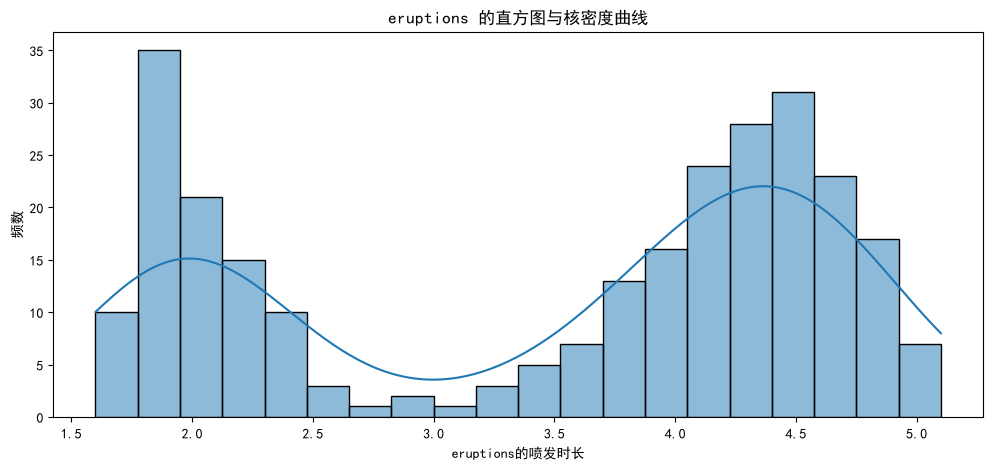

<Figure size 800x500 with 0 Axes>

In [5]:
df3=pd.read_csv('exercise2_2.csv',encoding='gbk',index_col=0)
plt.figure(figsize=(12,5))
sns.histplot(data=df3,x="eruptions",kde=True,bins=20)
plt.title('eruptions 的直方图与核密度曲线')
plt.xlabel('eruptions的喷发时长')
plt.ylabel('频数')
plt.figure(figsize=(8,5))
sns.kdeplot(data=df3,x='eruptions',label='eruptions',fill=True,color='red')
sns.kdeplot(data=df3,x='waiting',label='Waiting',fill=True,color='orange')
plt.title('Eruptions 与 Waiting 的核密度比较曲线')
plt.xlabel('数值')
plt.ylabel('密度 (Density)')
plt.legend() 
plt.show()

In [ ]:
plt.figure(figsize=(8,4))
sns.scatterplot(data=df3,x='eruptions',y='waiting',color='purple',alpha=0.4)
plt.title('散点图')
plt.xlabel('Eruptions')
plt.ylabel('Waiting')
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df3, x='mpg', y='wt', color='orange', alpha=0.5)
plt.xlabel('mpg')
plt.ylabel('wt')
plt.title('mpg 与 wt 的散点图')
plt.show()

In [ ]:
g = sns.pairplot(df3, corner=True, height=2, aspect=1)
g.fig.suptitle('数据集散点图矩阵', y=1.02) 
plt.show()

In [ ]:
plt.figure(figsize=(10,8))
corr = df3.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f',linewidths=.5)
plt.title('相关系数矩阵图')
plt.show()


In [ ]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(15,6))
ax1= fig.add_subplot(1,2,1)
scatter=ax1.scatter(x=df3['wt'],y=df3['mpg'],s=df3['hp'],c=df3['hp'],cmap='coolwarm',alpha=0.5,edgecolors='k')
ax1.set_title('气泡图')
ax1.set_xlabel('wt (汽车自重)')
ax1.set_ylabel('mpg (每加仑英里数)')
plt.colorbar(scatter, ax=ax1, label='hp (总马力)')
ax2=fig.add_subplot(1,2,2,projection='3d')
ax2.scatter(df3['wt'],df3['mpg'],df3['hp'],color='red',marker='o',alpha=0.99)
ax2.set_title('3D 散点图')
ax2.set_xlabel('wt (自重)')
ax2.set_ylabel('mpg (油耗)')
ax2.set_zlabel('hp (马力)')
plt.show

In [ ]:
print('第三章 描述性统计')
df4=pd.read_csv('exercise3_1.csv',encoding='gbk')
amount=df4['网购金额']
mean_val=amount.mean()
std_val=amount.std()
range_val=amount.max()-amount.min()
q1=amount.quantile(0.25)
q3=amount.quantile(0.75)
iqr_val=q3-q1
print(f"平均数: {mean_val:.2f}")
print(f"标准差: {std_val:.2f}")
print(f"极差: {range_val:.2f}")
print(f"四分位差(IQR): {iqr_val:.2f}")
quantiles = amount.quantile([0.1, 0.25, 0.5, 0.75, 0.9])
for q, val in quantiles.items():
    print(f'{int(q*100)}% 分位数：{val:.2f}')
z_scores = stats.zscore(amount)
outliers = df4[np.abs(z_scores)>2.5]
print(f'基于z的绝对值大于2.5的标准，共检测到{len(outliers)}个离群点')
if len(outliers) > 0 :
    print('具体的离群点如下：')
    print(outliers)
skew_val= amount.skew()
kurt_val= amount.kurt()
print(f'偏度系数:{skew_val:.2f}')
print(f'峰度系数:{kurt_val:.2f}')


In [ ]:
print('该数据集的偏度系数为 0.66。说明网购金额分布呈右偏（正偏）。这意味着大部分用户的网购金额低于平均水平，分布的长尾巴拖在右侧（即存在少数消费极高的用户拉高了平均值）。')
print('该数据集的峰度系数为1.22，说明分布呈一种尖峰厚尾的状态，意味着数据比起正态分布更加集中在平均值附近，且出现极端高消费值的概率比起正态分布更大')

In [ ]:
df5=pd.read_csv('exercise3_4.csv',encoding='gbk')
fig,axes = plt.subplots(2,2,figsize=(15,12))
sns.histplot(data=df5,x='月生活费支出',kde=True,bins=15,color="skyblue",ax=axes[0,0])
axes[0,0].set_title('月生活费支出直方图以及核密度曲线')
sns.kdeplot(data=df5,x='月生活费支出',hue='性别',fill=True,ax=axes[0,1])
axes[0,1].set_title('按照性别分组的和密度图')
sns.kdeplot(data=df5,x='月生活费支出',hue='家庭所在地',fill=True,ax=axes[1,0])
axes[1,0].set_title('按家庭所在地分组的核密度图')
sns.boxplot(data=df5, x='性别', y='月生活费支出', hue='家庭所在地', 
            width=0.5, 
            palette='Set2',
            showfliers=False, 
            boxprops=dict(alpha=0.5, edgecolor='#444444'), 
            whiskerprops=dict(color='#444444'),
            capprops=dict(color='#444444'),
            medianprops=dict(color='red', linewidth=2))
sns.stripplot(data=df5, x='性别', y='月生活费支出', hue='家庭所在地', 
              dodge=True, jitter=0.15, alpha=0.6, size=4, 
              palette='dark', ax=plt.gca(), legend=False)
axes[1,1].set_title('按性别和家庭所在地分组的箱线图和点图')
plt.tight_layout()
plt.show()

In [ ]:
def comprehensive_stats(series):
    return pd.Series({
        '频数(N)': len(series),
        '均值(Mean)': series.mean(),
        '标准差(Std)': series.std(),
        '最小值(Min)': series.min(),
        '25%分位(Q1)': series.quantile(0.25),
        '中位数(Median)': series.median(),
        '75%分位(Q3)': series.quantile(0.75),
        '最大值(Max)': series.max(),
        '极差(Range)': series.max() - series.min(),
        '四分位差(IQR)': series.quantile(0.75) - series.quantile(0.25),
        '偏度(Skew)': series.skew(),
        '峰度(Kurt)': series.kurt()
    })
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print("========== (1) 全部学生的描述性统计 ==========")
print(comprehensive_stats(df5['月生活费支出']).to_frame().T)
print("\n========== (2) 按性别分组 ==========")
print(df5.groupby('性别')['月生活费支出'].apply(comprehensive_stats).unstack())
print("\n========== (3) 按家庭所在地分组 ==========")
print(df5.groupby('家庭所在地')['月生活费支出'].apply(comprehensive_stats).unstack())
print("\n========== (4) 按性别和家庭所在地交叉分组 ==========")
print(df5.groupby(['性别', '家庭所在地'])['月生活费支出'].apply(comprehensive_stats).unstack())

In [ ]:
print('从全体学生的描述性统计来看，月生活费支出的均值为 1812.13 元，中位数为 1850 元。均值大于中位数，且偏度系数为0.32，说明整体分布呈右偏特征。这意味着大部分学生的生活费集中在较低水平，但存在少数极高消费的群体拉高了平均值。从直方图可以看出，数据存在明显的集中区间，峰度系数为 0.49，说明分布较为 集中。箱线图和点图显示，存在个别数值较高的离群点。根据按性别分组的统计表和箱线图：水平差异：女生 的平均生活费更高（男 1701 元 vs 女 1891 元），中位数也反映了同样的规律。离散程度差异：女生 的标准差和极差更大，说明该性别群体内部的消费分化更为严重，数据分布更分散。根据按家庭所在地分组的图表，消费水平呈现明显的阶梯式递减规律：来自大型城市的学生平均生活费最高（ 1848元），其次是中小城市（1795 元），乡镇地区的学生最低（1757元）。核密度图直观地证实了这一点：大型城市的曲线整体靠右（高消费），而乡镇地区的曲线峰值靠左（低消费）。')


In [ ]:
print('第四章：概率计算')
df6 = pd.read_csv('exercise4_1.csv', encoding='gbk')
df6.columns = df6.columns.str.strip()
prob1 = df6[(df6['X'] >= 2) & (df6['X'] <= 5)]['P'].sum()
print(f'有 2-5 台冷气机出现缺陷的概率为: {prob1:.4f}')
prob2 = df6[df6['X'] < 2]['P'].sum()
print(f"不到 2 台冷气机出现缺陷的概率为: {prob2:.4f}")
prob3 = df6[df6['X'] > 5]['P'].sum()
print(f"超过 5 台冷气机出现缺陷的概率为: {prob3:.4f}")

In [ ]:
mu1=500
sigma1=20
prob1=stats.norm.sf(510,loc=mu1,scale=sigma1)
print(f'P(X>=510) = {prob1:.4f}')
prob12=stats.norm.cdf(450,loc=mu1,scale=sigma1)-stats.norm.cdf(400,loc=mu1,scale=sigma1)
print(f'P(400<=X<=450) = {prob12:.4f}')
prob21 = stats.norm.cdf(1.2) - stats.norm.cdf(0)
print(f' P(0 <= Z <= 1.2) = {prob21:.4f}')
prob22 = stats.norm.cdf(0) - stats.norm.cdf(-0.48)
print(f"    P(-0.48 <= Z <= 0) = {prob22:.4f}")
prob23 = stats.norm.sf(1.2)
print(f"    P(Z >= 1.2) = {prob23:.4f}")
zvalue=stats.norm.ppf(0.95)
print(f' z的值：{zvalue:.4f}')




In [ ]:
p_t_1 = stats.t.cdf(-1.5, df=15)
print(f"df=15, P(t < -1.5) = {p_t_1:.4f}")
p_t_2 = stats.t.sf(2, df=20)
print(f"df=20, P(t > 2) = {p_t_2:.4f}")
t_val_1 = stats.t.isf(0.05, df=30)
print(f"df=30, 右尾概率为0.05时的 t 值 = {t_val_1:.4f}")
print("\n--- (2) 卡方分布 χ² ---")
p_chi2_1 = stats.chi2.cdf(12, df=8)
print(f"df=8, P(χ² < 12) = {p_chi2_1:.4f}")
p_chi2_2 = stats.chi2.sf(18, df=20)
print(f"df=20, P(χ² > 18) = {p_chi2_2:.4f}")
chi2_val = stats.chi2.isf(0.025, df=15)
print(f"df=15, 右尾概率为0.025时的 χ² 值 = {chi2_val:.4f}")
print("\n--- (3) F 分布 ---")
p_f_1 = stats.f.cdf(3.5, dfn=15, dfd=10)
print(f"df1=15, df2=10, P(F < 3.5) = {p_f_1:.4f}")
p_f_2 = stats.f.sf(3, dfn=12, dfd=8)
print(f"df1=12, df2=8, P(F > 3) = {p_f_2:.4f}")
f_val = stats.f.isf(0.025, dfn=20, dfd=16)
print(f"df1=20, df2=16, 右尾概率为0.025时的 F 值 = {f_val:.4f}")


In [ ]:
print('第五章 参数估计')
df7=pd.read_csv('exercise5_2.csv',encoding='gbk')
df7.columns = df7.columns.str.strip()
data1 = df7['方式1']
data2 = df7['方式2']
n1= len (data1)
n2= len(data2)
mean1 = data1.mean()
std1= data1.std(ddof=1)
se1 = std1/np.sqrt(n1)
tcrit1=stats.t.ppf(0.975,df=n1-1)
ci_mean1=(mean1-tcrit1*se1 ,mean1+tcrit1*se1)
print(f"(1) 方式1 均值的95%置信区间: [{ci_mean1[0]:.4f}, {ci_mean1[1]:.4f}]")
var2 = data2.var(ddof=1)
chi2_lower = stats.chi2.ppf(0.025, df=n2-1)
chi2_upper = stats.chi2.ppf(0.975, df=n2-1)
ci_var2_lower = (n2 - 1) * var2 / chi2_upper
ci_var2_upper = (n2 - 1) * var2 / chi2_lower
print(f"(2) 方式2 方差的95%置信区间: [{ci_var2_lower:.4f}, {ci_var2_upper:.4f}]")
ds1 = DescrStatsW(data1)
ds2 = DescrStatsW(data2)
cm = CompareMeans(ds1, ds2)
ci_diff = cm.tconfint_diff(alpha=0.05, alternative='two-sided', usevar='unequal')
print(f"(3) 两种方式均值差的95%置信区间: [{ci_diff[0]:.4f}, {ci_diff[1]:.4f}]")

In [ ]:
n1=250
p1_hat=0.4
n2=250
p2_hat=0.3
p_diff = p1_hat - p2_hat
se = np.sqrt((p1_hat * (1 - p1_hat) / n1) + (p2_hat * (1 - p2_hat) / n2))
z_90 = stats.norm.ppf(0.95) 
z_95 = stats.norm.ppf(0.975)
ci_90_lower = p_diff - z_90 * se
ci_90_upper = p_diff + z_90 * se
ci_95_lower = p_diff - z_95 * se
ci_95_upper = p_diff + z_95 * se
print(f"样本比例差 (p1 - p2): {p_diff:.4f}")
print(f"SE: {se:.4f}")
print(f"90% 的置信区间: [{ci_90_lower:.4f}, {ci_90_upper:.4f}]")
print(f"即： [{ci_90_lower*100:.2f}%, {ci_90_upper*100:.2f}%]")
print(f"95% 的置信区间: [{ci_95_lower:.4f}, {ci_95_upper:.4f}]")
print(f"即： [{ci_95_lower*100:.2f}%, {ci_95_upper*100:.2f}%]")